Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


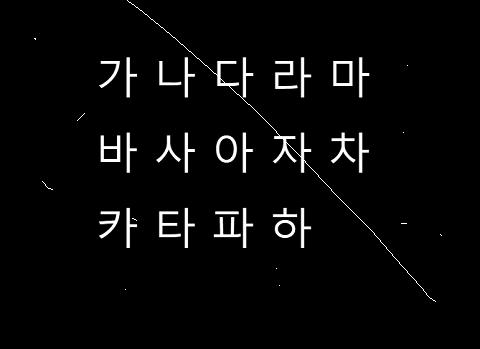

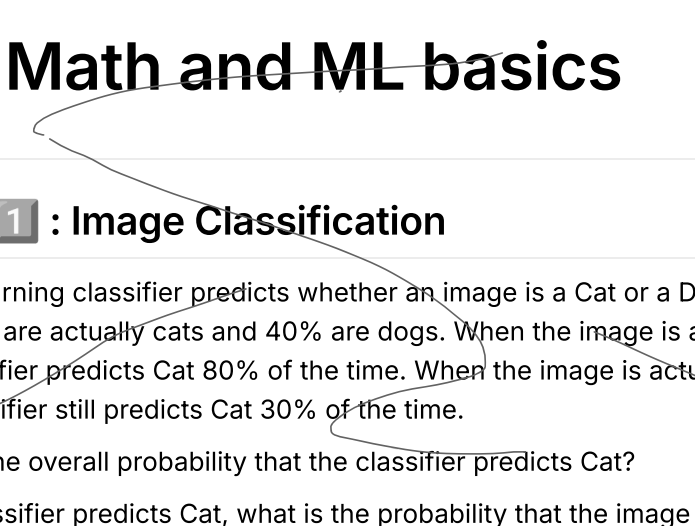

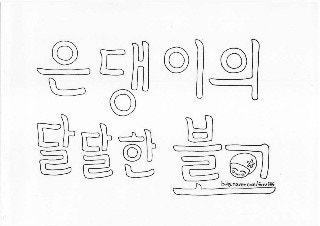

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
#origin image

noise_t1 = "/content/drive/MyDrive/ComputerVision/noise text1.png"
noise_t2 = "/content/drive/MyDrive/ComputerVision/noise text2.png"
noise_t3 = "/content/drive/MyDrive/ComputerVision/noise text3.jpg"

nt1 = cv2.imread(noise_t1, cv2.IMREAD_GRAYSCALE)
nt2 = cv2.imread(noise_t2, cv2.IMREAD_GRAYSCALE)
nt3 = cv2.imread(noise_t3, cv2.IMREAD_GRAYSCALE)

cv2_imshow(nt1)
cv2_imshow(nt2)
cv2_imshow(nt3)


#binary

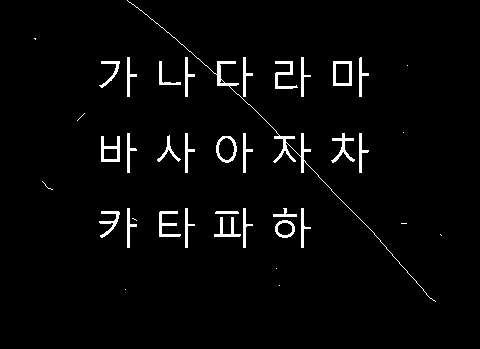

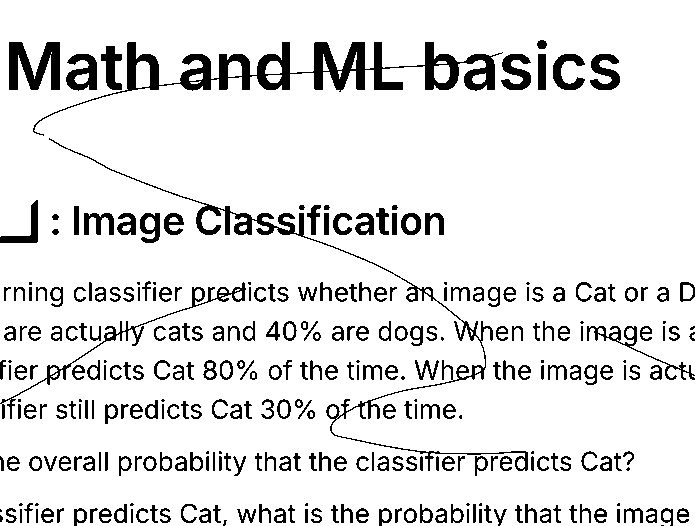

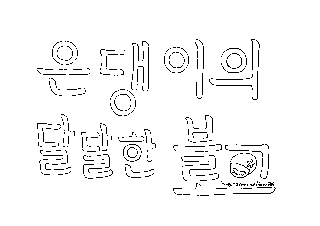

In [ ]:
threshold_value = 150

_, nt1_bin = cv2.threshold(nt1, threshold_value, 255, cv2.THRESH_BINARY)
_, nt2_bin = cv2.threshold(nt2, threshold_value, 255, cv2.THRESH_BINARY)
_, nt3_bin = cv2.threshold(nt3, threshold_value, 255, cv2.THRESH_BINARY)


cv2_imshow(nt1_bin)
cv2_imshow(nt2_bin)
cv2_imshow(nt3_bin)


#dilation & erosion

dilate - Cross-shape


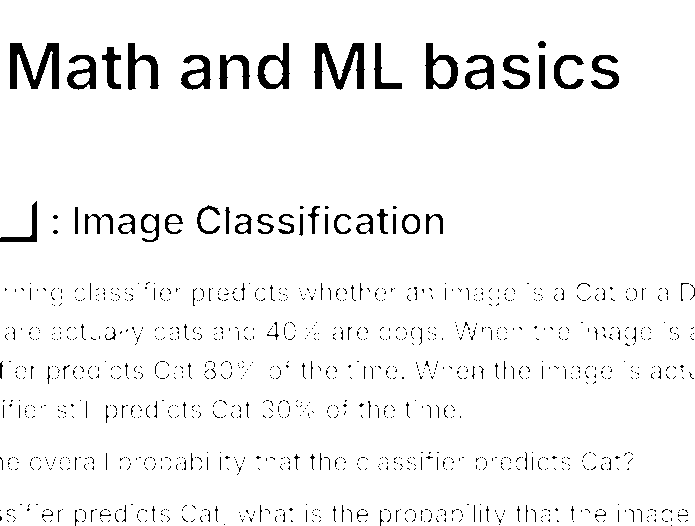


 
dilate - Square


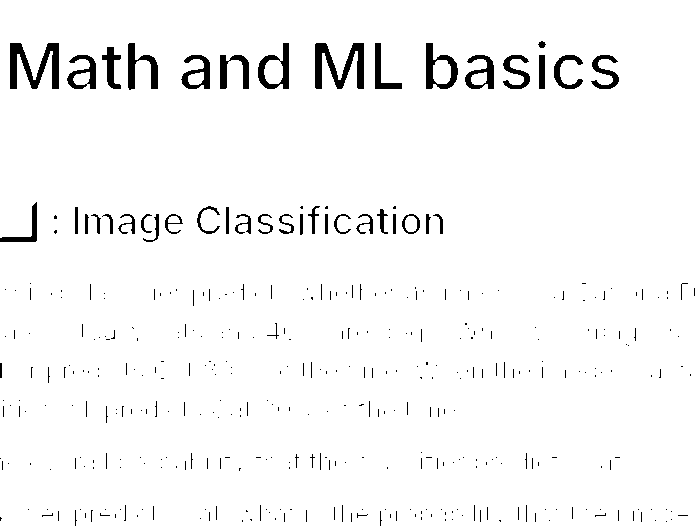


 
dilate - Vertical line


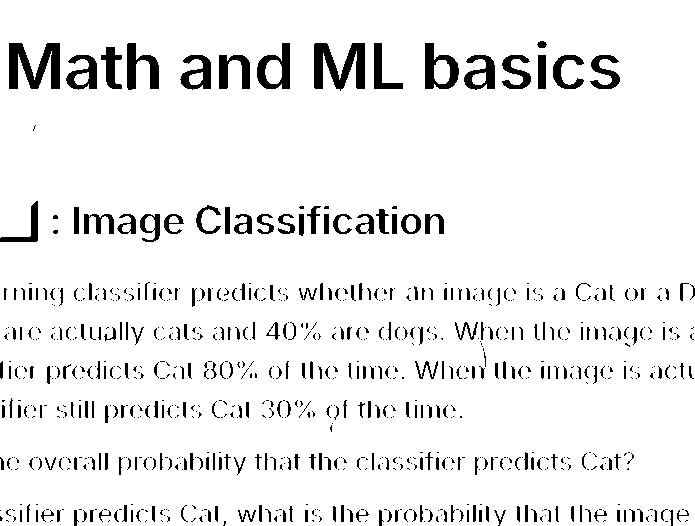


 
dilate - Horizontal line


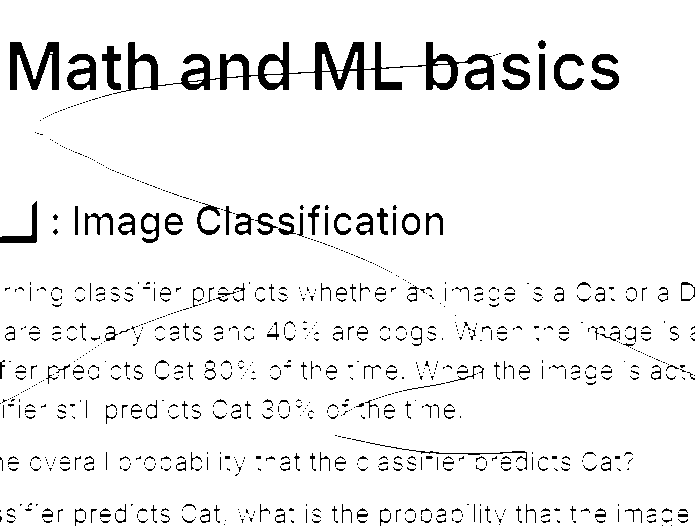


 
erod - Cross-shape


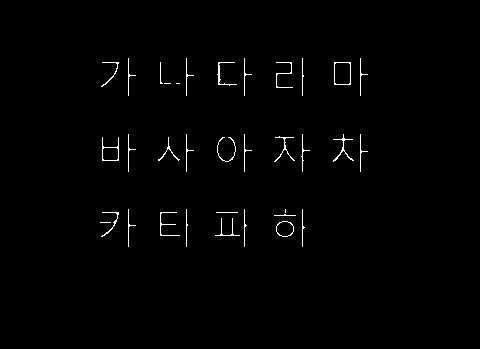


 
erod - Square


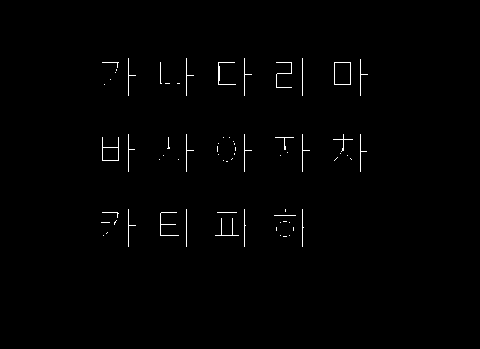


 
erod - Vertical line


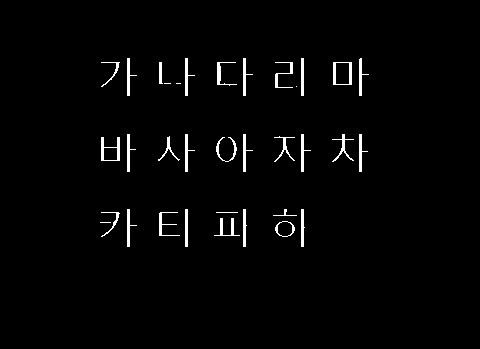


 
erod - Horizontal line


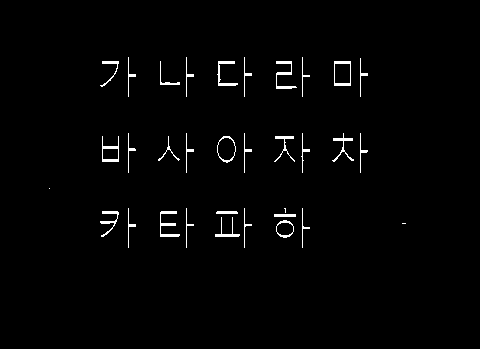

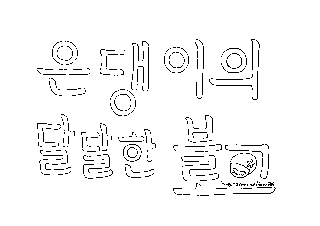

erod - Cross-shape


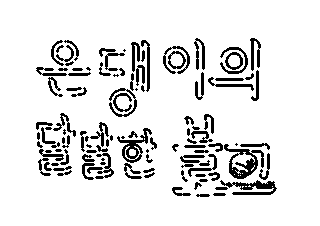


 
erod - Square


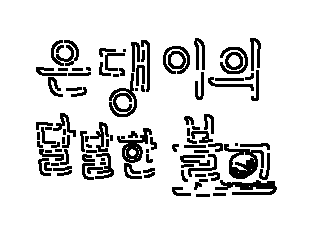


 
erod - Vertical line


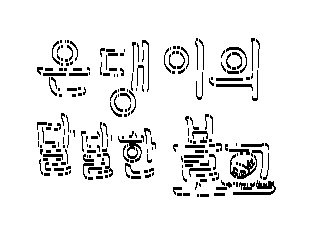


 
erod - Horizontal line


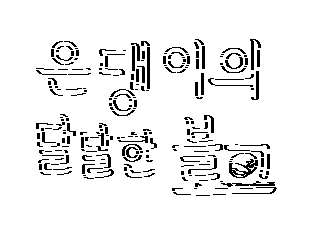

In [ ]:

# 2. 3x3
from skimage.morphology import diamond

se_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3,3))
se_square = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
se_vline = cv2.getStructuringElement(cv2.MORPH_RECT, (1,3))
se_hline = cv2.getStructuringElement(cv2.MORPH_RECT, (3,1))

structuring_elements = {
    "Cross-shape": se_cross,
    "Square": se_square,
    "Vertical line": se_vline,
    "Horizontal line": se_hline,
}

# 3. Dilation
for title, se in structuring_elements.items():
    print("dilate -", title)
    dila = cv2.dilate(nt2_bin, se)
    dila2= cv2.dilate(nt3_bin, se)
    cv2_imshow(dila)
    print("\n \n ==================================")

# 4. Erosion
for title, se in structuring_elements.items():
    print("erod -", title)
    erod = cv2.erode(nt1_bin, se)
    cv2_imshow(erod)
    print("\n \n ==================================")

cv2_imshow(nt3_bin)
for title, se in structuring_elements.items():
    print("erod -", title)
    erod = cv2.erode(nt3_bin, se)
    cv2_imshow(erod)
    print("\n \n ==================================")

#opening and closing

===== nt1 : 원본 =====


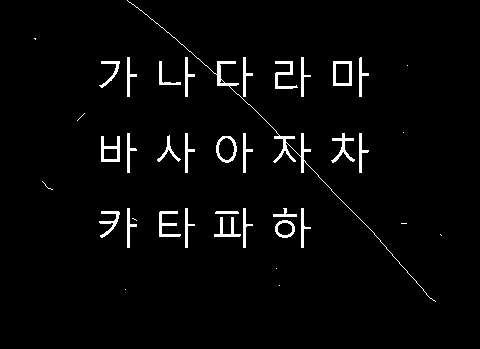

open - nt1 - Cross-shape


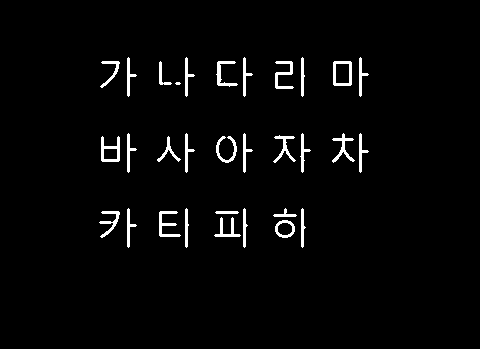


 
open - nt1 - Square


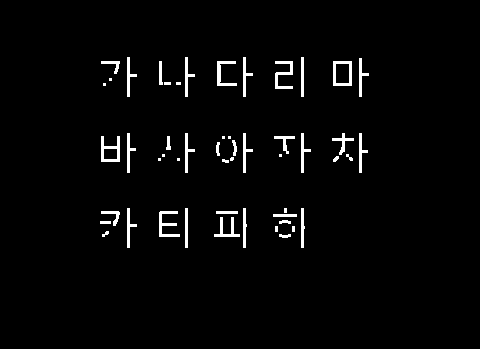


 
open - nt1 - Vertical line


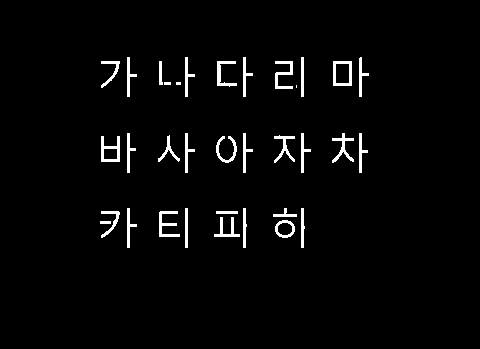


 
open - nt1 - Horizontal line


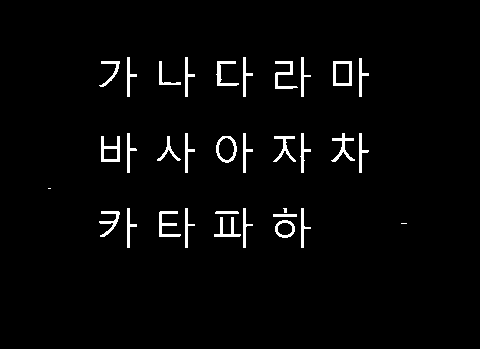


 
===== nt2 : 원본 =====


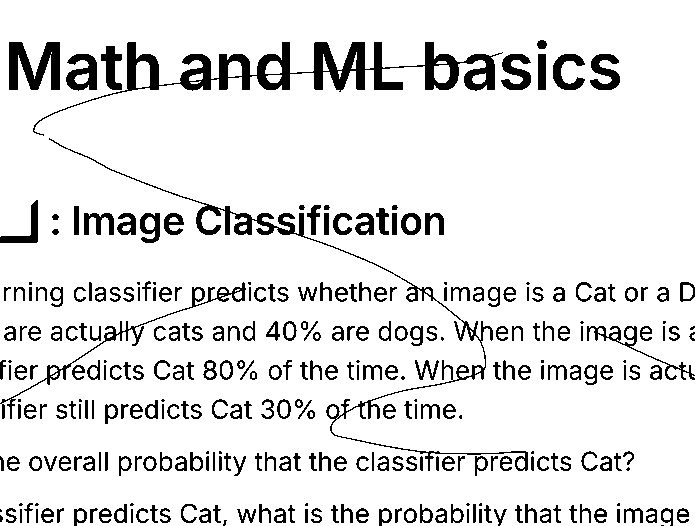

open - nt2 - Cross-shape


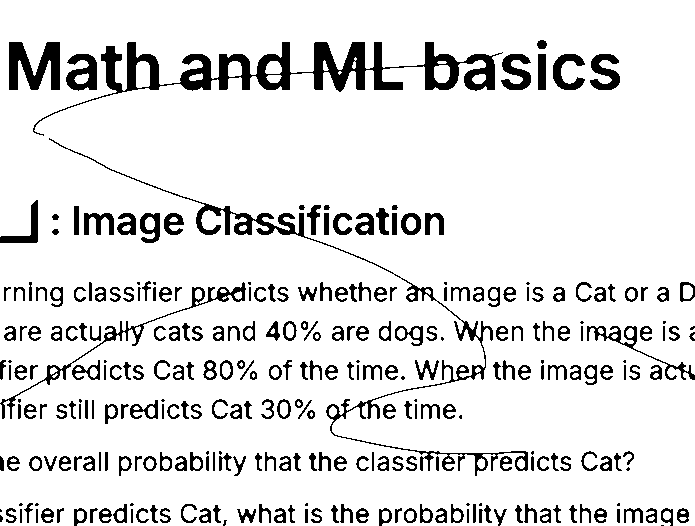


 
open - nt2 - Square


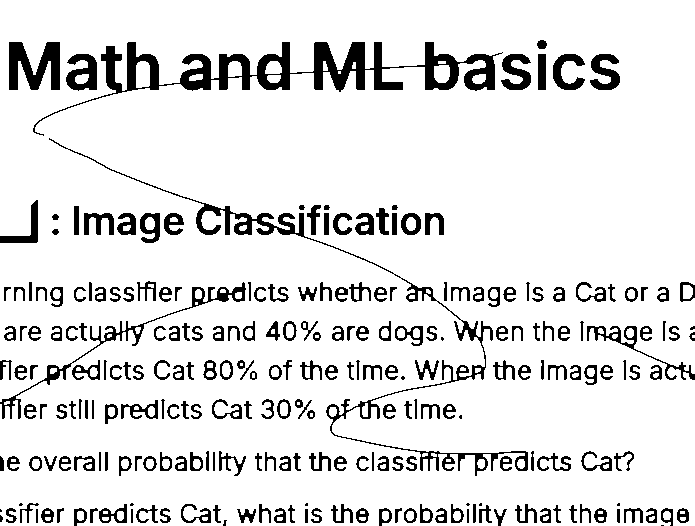


 
open - nt2 - Vertical line


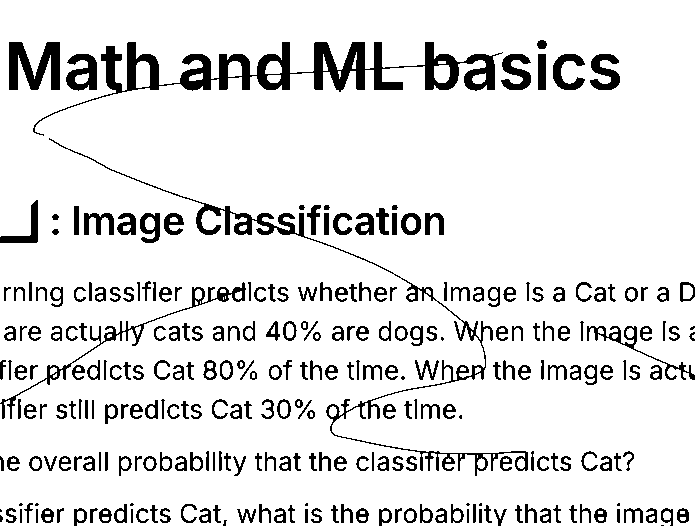


 
open - nt2 - Horizontal line


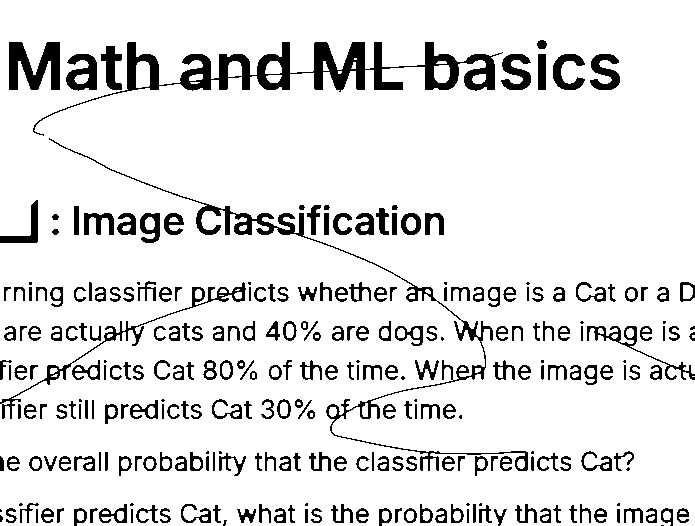


 
close - nt1 - Cross-shape


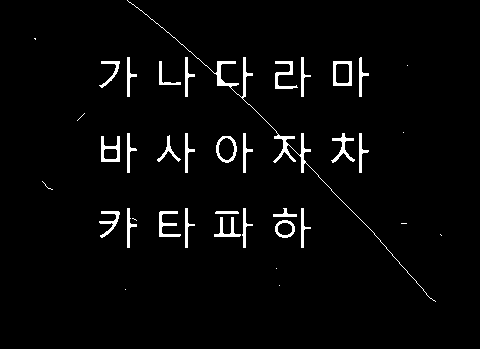


 
close - nt1 - Square


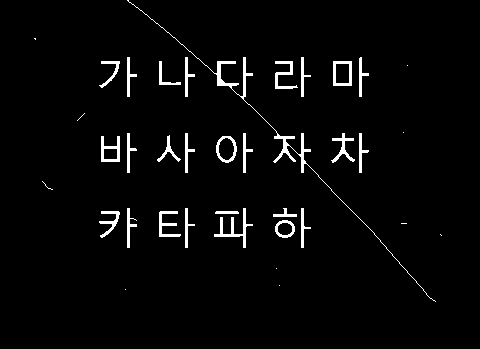


 
close - nt1 - Vertical line


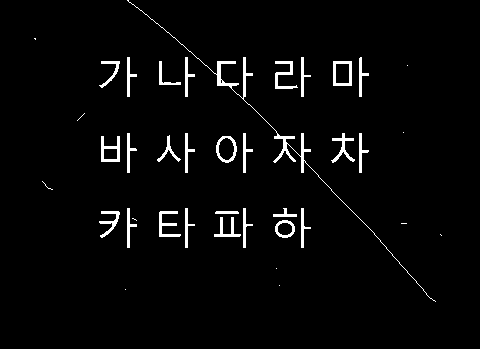


 
close - nt1 - Horizontal line


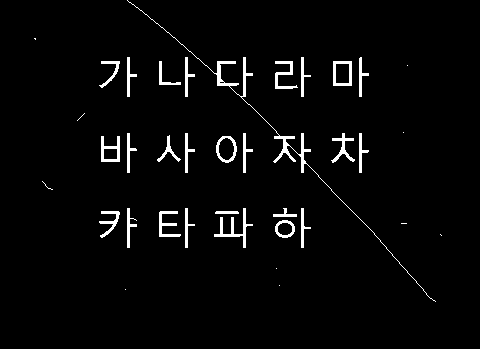


 
close - nt2 - Cross-shape


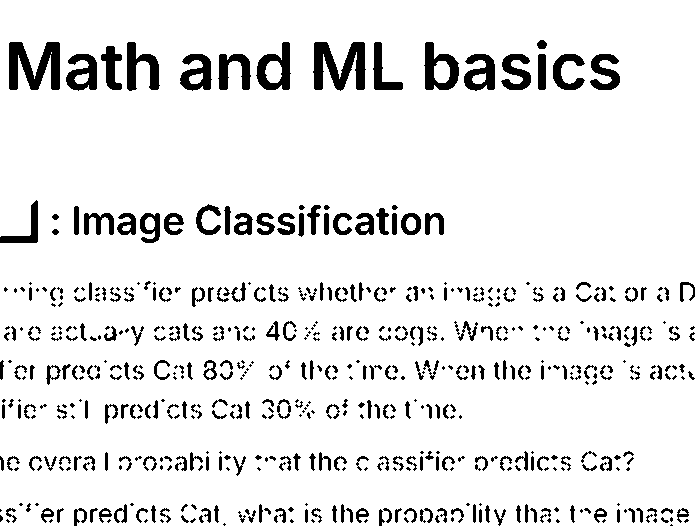


 
close - nt2 - Square


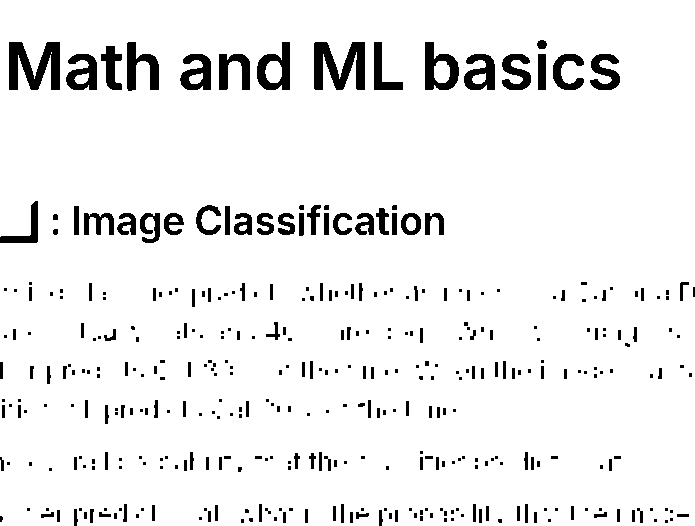


 
close - nt2 - Vertical line


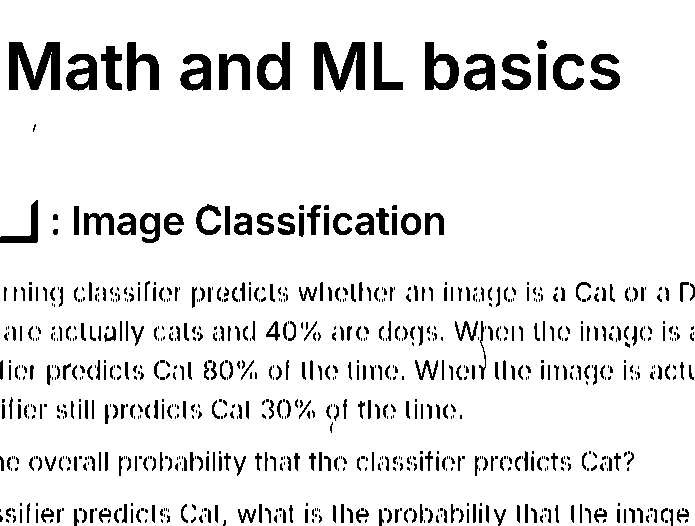


 
close - nt2 - Horizontal line


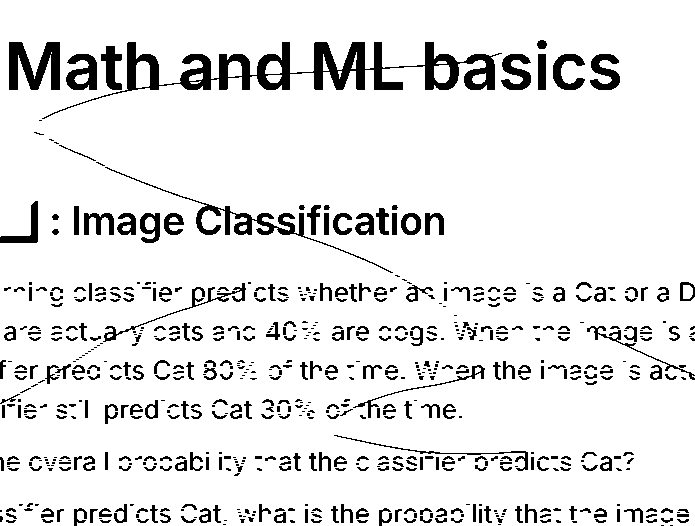

In [ ]:
import cv2
import numpy as np
from skimage.morphology import diamond

# 구조 요소 (3x3)
se_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3,3))
se_square = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
se_vline = cv2.getStructuringElement(cv2.MORPH_RECT, (1,3))
se_hline = cv2.getStructuringElement(cv2.MORPH_RECT, (3,1))

structuring_elements = {
    "Cross-shape": se_cross,
    "Square": se_square,
    "Vertical line": se_vline,
    "Horizontal line": se_hline,
}

images = {"nt1": nt1_bin, "nt2": nt2_bin}

# 5. Opening
for name, img in images.items():
    print(f"===== {name} : 원본 =====")
    cv2_imshow(img)
    for title, se in structuring_elements.items():
        print("open -", name, "-", title)
        opened = cv2.morphologyEx(img, cv2.MORPH_OPEN, se)
        cv2_imshow(opened)
        print("\n \n ==================================")

# 6. Closing
for name, img in images.items():
    for title, se in structuring_elements.items():
        print("close -", name, "-", title)
        closed = cv2.morphologyEx(img, cv2.MORPH_CLOSE, se)
        cv2_imshow(closed)
        print("\n \n ==================================")

